In [1]:
# ============================================
# CELL 1: Install, import, and load the dataset
# ============================================

# Install the helper package that downloads datasets directly from UCI
!pip install ucimlrepo -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

# Reproducibility: we'll reuse this number all project long
RANDOM_STATE = 42

# Make tables and plots look cleaner
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Download dataset ID 468 = Online Shoppers Purchasing Intention
dataset = fetch_ucirepo(id=468)

# The package returns features (X) and target (y) separately.
# For exploration, we join them into one DataFrame.
df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)

print("Dataset loaded successfully!")
print("Shape (rows, columns):", df.shape)

Dataset loaded successfully!
Shape (rows, columns): (12330, 18)


In [2]:
# ============================================
# CELL 2: First look at the data
# ============================================

print("=== FIRST 5 ROWS ===")
display(df.head())

print("\n=== LAST 5 ROWS ===")
display(df.tail())

print("\n=== DIMENSIONS ===")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n=== COLUMN NAMES AND DATA TYPES ===")
print(df.dtypes)

print("\n=== CONCISE INFO ===")
df.info()

=== FIRST 5 ROWS ===


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



=== LAST 5 ROWS ===


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False
12329,0,0.0,0,0.0,3,21.250000,0.000000,0.066667,0.000000,0.0,Nov,3,2,1,2,New_Visitor,True,False



=== DIMENSIONS ===
Rows: 12330, Columns: 18

=== COLUMN NAMES AND DATA TYPES ===
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object

=== CONCISE INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330

=== MISSING VALUES PER COLUMN ===
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64
Total missing values: 0

=== DUPLICATES ===
Duplicate rows: 125 (1.01% of the data)

=== TARGET: Revenue ===
         count  percent
Revenue                
False    10422    84.53
True      1908    15.47

Imbalance ratio (majority : minority) = 5.46 : 1


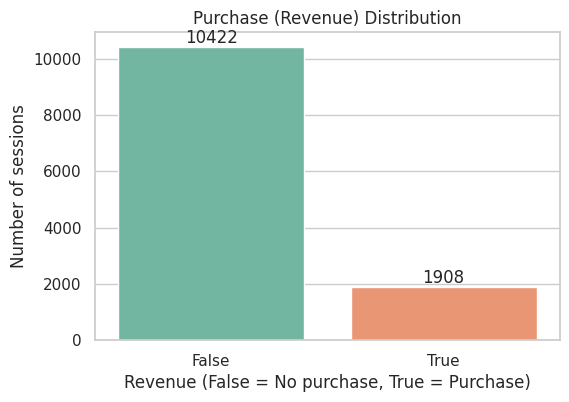


=== NUMERIC SUMMARY ===


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [3]:
# ============================================
# CELL 3: Data quality checks and target analysis
# ============================================

# --- Missing values ---
print("=== MISSING VALUES PER COLUMN ===")
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

# --- Duplicate rows ---
n_dupes = df.duplicated().sum()
print(f"\n=== DUPLICATES ===")
print(f"Duplicate rows: {n_dupes} ({n_dupes / len(df) * 100:.2f}% of the data)")

# --- Target variable ---
print("\n=== TARGET: Revenue ===")
counts = df["Revenue"].value_counts()
percent = df["Revenue"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": percent.round(2)}))

ratio = counts.max() / counts.min()
print(f"\nImbalance ratio (majority : minority) = {ratio:.2f} : 1")

# --- Visualize the target ---
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Revenue", hue="Revenue", palette="Set2", legend=False)
for container in ax.containers:
    ax.bar_label(container)
plt.title("Purchase (Revenue) Distribution")
plt.xlabel("Revenue (False = No purchase, True = Purchase)")
plt.ylabel("Number of sessions")
plt.show()

# --- Quick statistical summary of numeric columns ---
print("\n=== NUMERIC SUMMARY ===")
display(df.describe().T)

=== VisitorType ===
                   count  percent
VisitorType                      
Returning_Visitor  10551    85.57
New_Visitor         1694    13.74
Other                 85     0.69

=== Month ===
       count  percent
Month                
May     3364    27.28
Nov     2998    24.31
Mar     1907    15.47
Dec     1727    14.01
Oct      549     4.45
Sep      448     3.63
Aug      433     3.51
Jul      432     3.50
June     288     2.34
Feb      184     1.49

=== Weekend ===
         count  percent
Weekend                
False     9462    76.74
True      2868    23.26

Months present in data: ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
Months in data but not in my list: set()


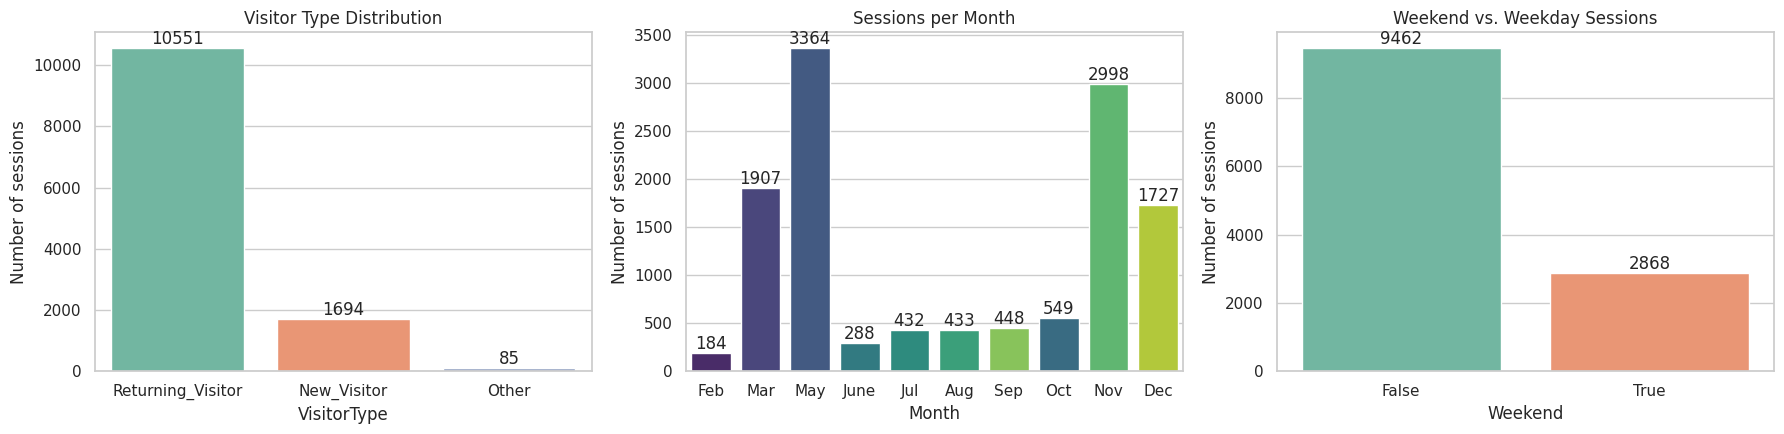


=== CATEGORY-CODE COLUMNS ===
OperatingSystems: 8 unique codes | top 3 codes cover 95.2% of sessions
OperatingSystems
2    53.54
1    20.97
3    20.72
4     3.88
8     0.64

Browser: 13 unique codes | top 3 codes cover 90.5% of sessions
Browser
2    64.57
1    19.97
4     5.97
5     3.79
6     1.41

Region: 9 unique codes | top 3 codes cover 67.8% of sessions
Region
1    38.77
3    19.49
4     9.59
2     9.21
6     6.53

TrafficType: 20 unique codes | top 3 codes cover 68.3% of sessions
TrafficType
2     31.74
1     19.88
3     16.64
4      8.67
13     5.99



In [4]:
# ============================================
# CELL 4: Univariate analysis - categorical features
# ============================================

# --- Part 1: text/boolean categories ---
for col in ["VisitorType", "Month", "Weekend"]:
    print(f"=== {col} ===")
    vc = df[col].value_counts()
    print(pd.DataFrame({"count": vc, "percent": (vc / len(df) * 100).round(2)}))
    print()

# Natural calendar order, keeping only months that exist in the data
all_months = ["Jan", "Feb", "Mar", "Apr", "May", "June",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_order = [m for m in all_months if m in df["Month"].unique()]
print("Months present in data:", month_order)
print("Months in data but not in my list:", set(df["Month"].unique()) - set(all_months))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

sns.countplot(data=df, x="VisitorType", hue="VisitorType", palette="Set2",
              legend=False, order=df["VisitorType"].value_counts().index, ax=axes[0])
axes[0].set_title("Visitor Type Distribution")

sns.countplot(data=df, x="Month", hue="Month", palette="viridis",
              legend=False, order=month_order, ax=axes[1])
axes[1].set_title("Sessions per Month")

sns.countplot(data=df, x="Weekend", hue="Weekend", palette="Set2",
              legend=False, ax=axes[2])
axes[2].set_title("Weekend vs. Weekday Sessions")

for ax in axes:
    for container in ax.containers:
        ax.bar_label(container)
    ax.set_ylabel("Number of sessions")

plt.tight_layout()
plt.show()

# --- Part 2: integer columns that are really category codes ---
print("\n=== CATEGORY-CODE COLUMNS ===")
for col in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
    vc = df[col].value_counts(normalize=True) * 100
    print(f"{col}: {df[col].nunique()} unique codes | "
          f"top 3 codes cover {vc.head(3).sum():.1f}% of sessions")
    print(vc.head(5).round(2).to_string())
    print()

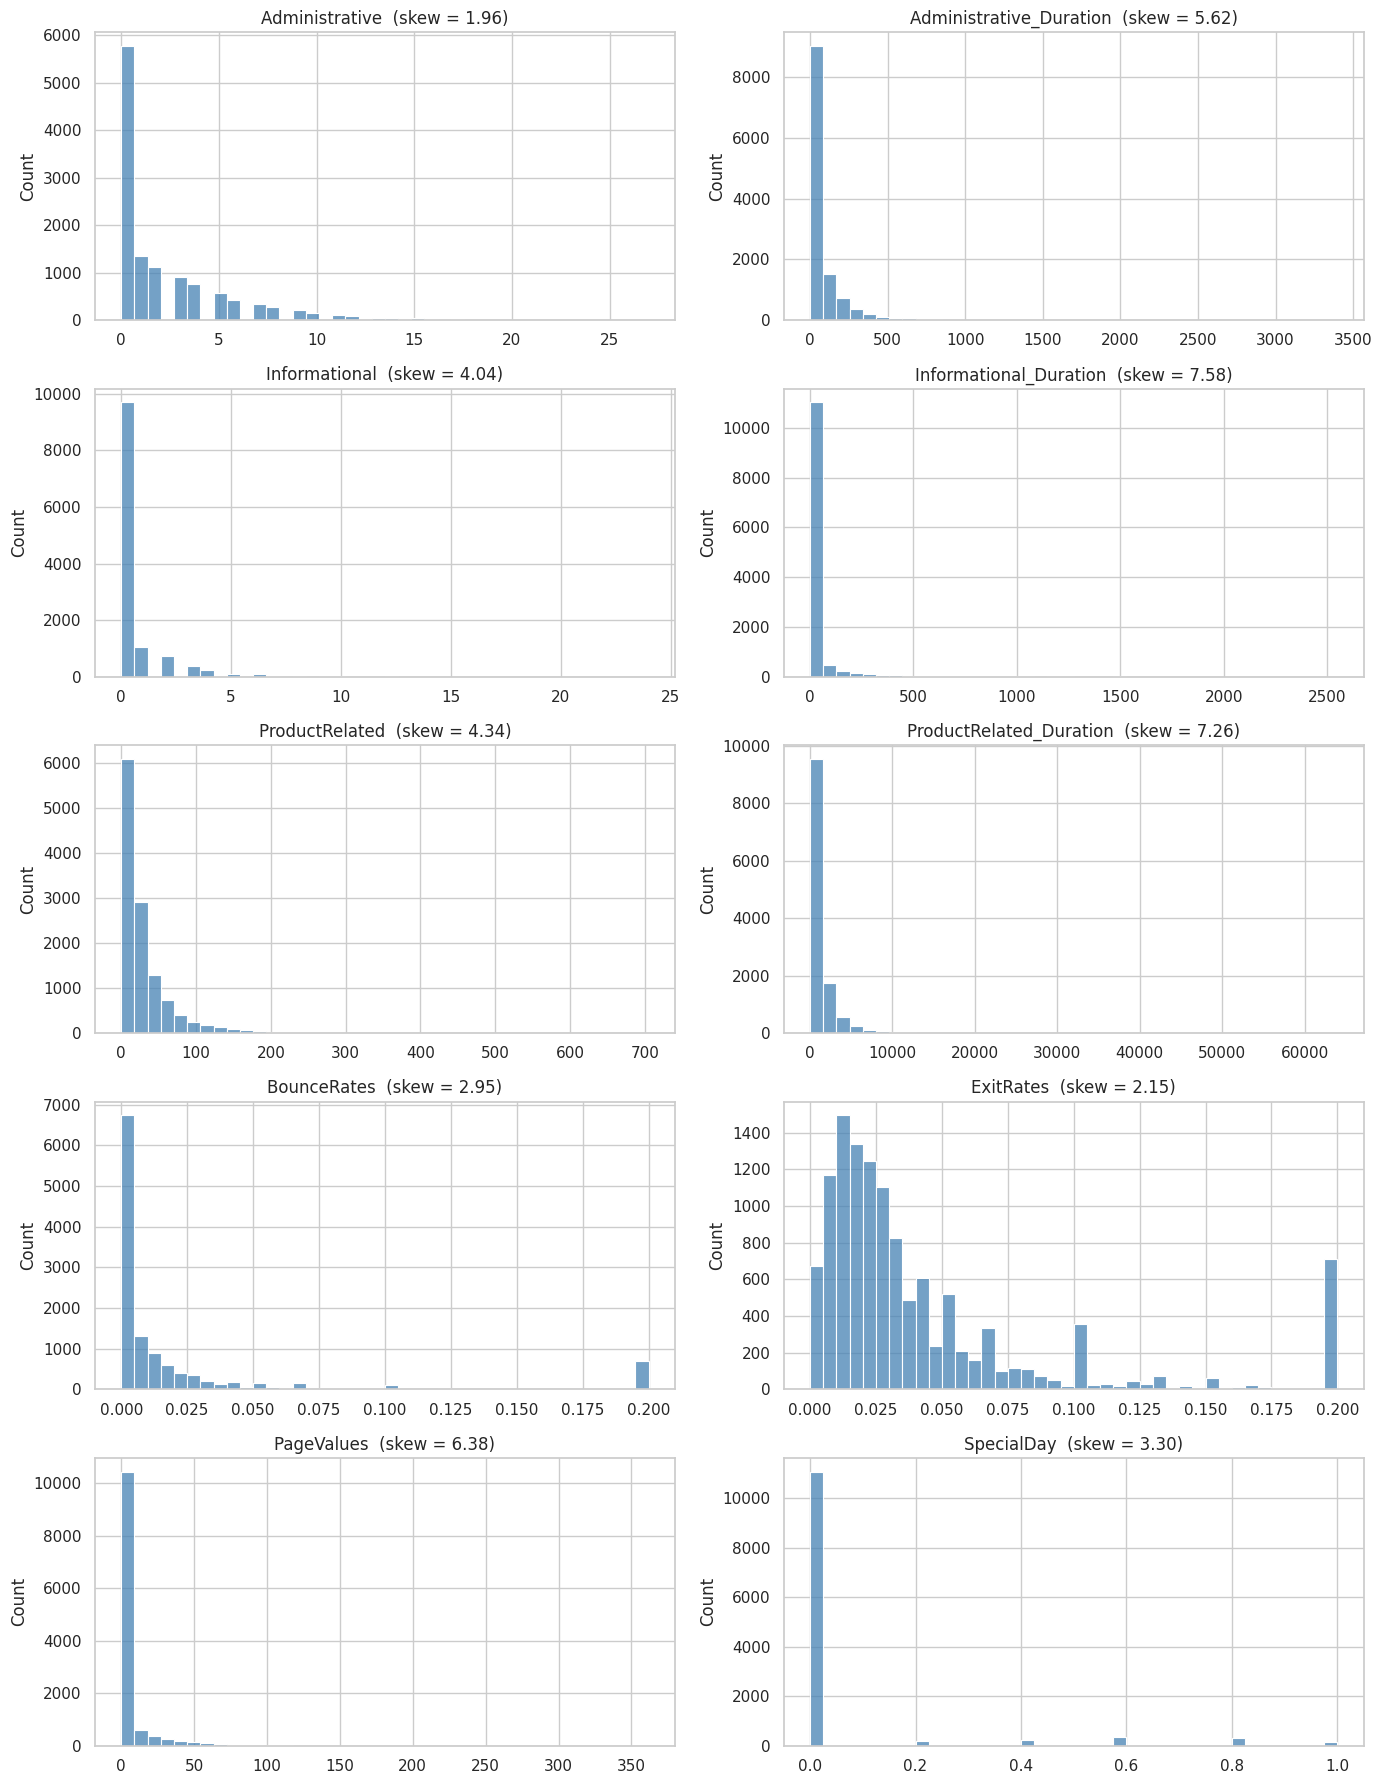

                         pct_zero  median     mean       max  skewness
Informational_Duration      80.49    0.00    34.47   2549.38      7.58
ProductRelated_Duration      6.12  598.94  1194.75  63973.52      7.26
PageValues                  77.86    0.00     5.89    361.76      6.38
Administrative_Duration     47.88    7.50    80.82   3398.75      5.62
ProductRelated               0.31   18.00    31.73    705.00      4.34
Informational               78.66    0.00     0.50     24.00      4.04
SpecialDay                  89.85    0.00     0.06      1.00      3.30
BounceRates                 44.75    0.00     0.02      0.20      2.95
ExitRates                    0.62    0.03     0.04      0.20      2.15
Administrative              46.78    1.00     2.32     27.00      1.96

=== OUTLIER COUNT (IQR rule) ===
Administrative: 404 (3.3%)
Administrative_Duration: 1172 (9.5%)
Informational: 2631 (21.3%)
Informational_Duration: 2405 (19.5%)
ProductRelated: 987 (8.0%)
ProductRelated_Duration: 961 

In [5]:
# ============================================
# CELL 5: Univariate analysis - numeric features
# ============================================

num_cols = ["Administrative", "Administrative_Duration",
            "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration",
            "BounceRates", "ExitRates", "PageValues", "SpecialDay"]

# --- Histograms ---
fig, axes = plt.subplots(5, 2, figsize=(14, 18))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(df[col], bins=40, ax=ax, color="steelblue")
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

# --- Summary: how many zeros, how skewed, how big are the outliers ---
summary = pd.DataFrame({
    "pct_zero": (df[num_cols] == 0).mean() * 100,
    "median": df[num_cols].median(),
    "mean": df[num_cols].mean(),
    "max": df[num_cols].max(),
    "skewness": df[num_cols].skew(),
}).round(2)
print(summary.sort_values("skewness", ascending=False))

# --- Outliers by the IQR rule (reported only; we are NOT removing anything) ---
print("\n=== OUTLIER COUNT (IQR rule) ===")
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n_out} ({n_out / len(df) * 100:.1f}%)")

In [6]:
# ============================================
# CELL 5b: Pages viewed but zero time recorded?
# ============================================
pairs = [("Administrative", "Administrative_Duration"),
         ("Informational", "Informational_Duration"),
         ("ProductRelated", "ProductRelated_Duration")]

for count_col, dur_col in pairs:
    pages_no_time = ((df[count_col] > 0) & (df[dur_col] == 0)).sum()
    time_no_pages = ((df[count_col] == 0) & (df[dur_col] > 0)).sum()
    print(f"{count_col}: pages>0 but duration=0 -> {pages_no_time} sessions | "
          f"pages=0 but duration>0 -> {time_no_pages} sessions")

Administrative: pages>0 but duration=0 -> 135 sessions | pages=0 but duration>0 -> 0 sessions
Informational: pages>0 but duration=0 -> 226 sessions | pages=0 but duration>0 -> 0 sessions
ProductRelated: pages>0 but duration=0 -> 717 sessions | pages=0 but duration>0 -> 0 sessions


Overall purchase rate: 15.47%

=== Purchase rate by VisitorType ===
                   sessions  purchases   rate
VisitorType                                  
New_Visitor            1694        422  24.91
Other                    85         16  18.82
Returning_Visitor     10551       1470  13.93

=== Purchase rate by Month ===
       sessions  purchases   rate
Month                            
Aug         433         76  17.55
Dec        1727        216  12.51
Feb         184          3   1.63
Jul         432         66  15.28
June        288         29  10.07
Mar        1907        192  10.07
May        3364        365  10.85
Nov        2998        760  25.35
Oct         549        115  20.95
Sep         448         86  19.20

=== Purchase rate by Weekend ===
         sessions  purchases   rate
Weekend                            
False        9462       1409  14.89
True         2868        499  17.40

=== Purchase rate by SpecialDay ===
            sessions  purchases   rate
SpecialD

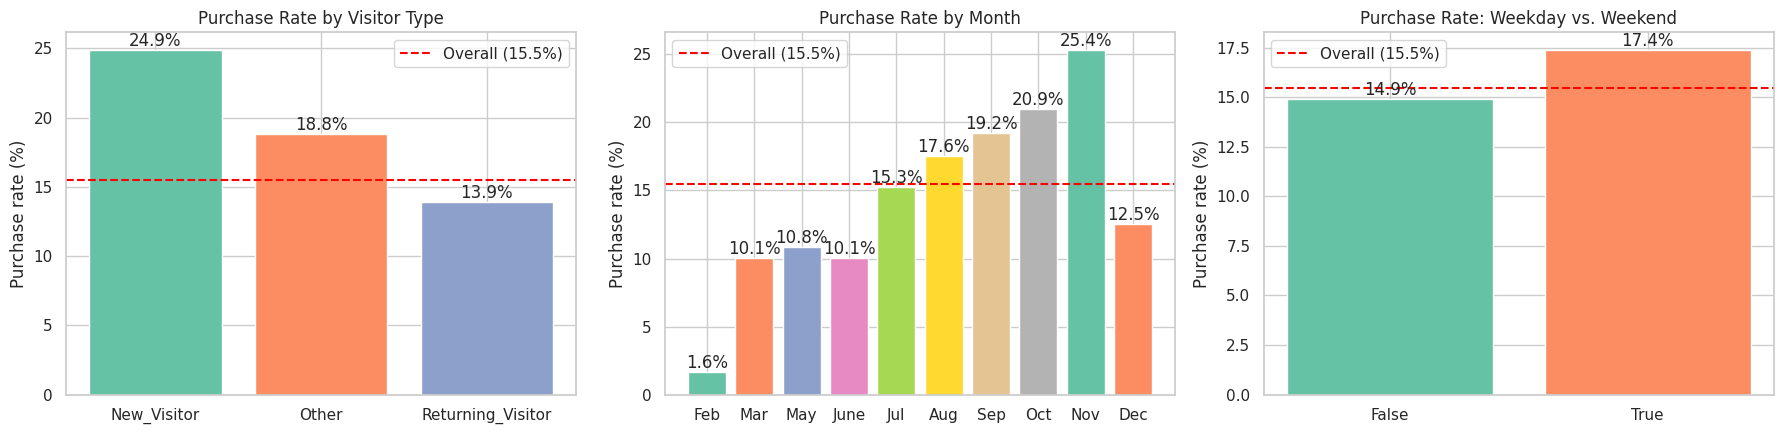

=== Purchase rate by OperatingSystems (groups with 100+ sessions) ===
                  sessions  purchases   rate
OperatingSystems                            
4                      478         85  17.78
2                     6601       1155  17.50
1                     2585        379  14.66
3                     2555        268  10.49

=== Purchase rate by Browser (groups with 100+ sessions) ===
         sessions  purchases   rate
Browser                            
10            163         32  19.63
5             467         86  18.42
4             736        130  17.66
8             135         21  15.56
2            7961       1223  15.36
1            2462        365  14.83
6             174         20  11.49
3             105          5   4.76

=== Purchase rate by Region (groups with 100+ sessions) ===
        sessions  purchases   rate
Region                            
9            511         86  16.83
2           1136        188  16.55
5            318         52  16.35
1 

In [7]:
# ============================================
# CELL 6: Bivariate analysis - categorical features vs Revenue
# ============================================

overall_rate = df["Revenue"].mean() * 100
print(f"Overall purchase rate: {overall_rate:.2f}%\n")

def rate_table(col):
    """Sessions, purchases and purchase rate (%) for each value of `col`."""
    t = df.groupby(col)["Revenue"].agg(sessions="count", purchases="sum", rate="mean")
    t["rate"] = (t["rate"] * 100).round(2)
    return t

# --- Tables ---
for col in ["VisitorType", "Month", "Weekend", "SpecialDay"]:
    print(f"=== Purchase rate by {col} ===")
    print(rate_table(col))
    print()

# --- Plots: purchase rate with the overall rate as a dashed line ---
all_months = ["Jan", "Feb", "Mar", "Apr", "May", "June",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_order = [m for m in all_months if m in df["Month"].unique()]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

vt = rate_table("VisitorType").sort_values("rate", ascending=False)
mo = rate_table("Month").reindex(month_order)
wk = rate_table("Weekend")

for ax, tbl, title in zip(axes, [vt, mo, wk],
                          ["Purchase Rate by Visitor Type",
                           "Purchase Rate by Month",
                           "Purchase Rate: Weekday vs. Weekend"]):
    bars = ax.bar(tbl.index.astype(str), tbl["rate"], color=sns.color_palette("Set2", len(tbl)))
    ax.axhline(overall_rate, color="red", linestyle="--", label=f"Overall ({overall_rate:.1f}%)")
    ax.bar_label(bars, fmt="%.1f%%")
    ax.set_title(title)
    ax.set_ylabel("Purchase rate (%)")
    ax.legend()

plt.tight_layout()
plt.show()

# --- Category-code columns: look at them, but flag small groups ---
for col in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
    print(f"=== Purchase rate by {col} (groups with 100+ sessions) ===")
    t = rate_table(col)
    print(t[t["sessions"] >= 100].sort_values("rate", ascending=False))
    print()

=== Non-buyers (False) vs Buyers (True) ===
Revenue                          False   True 
Administrative          median     0.0     2.0
                        mean       2.1     3.4
Informational           median     0.0     0.0
                        mean       0.5     0.8
ProductRelated          median    16.0    29.0
                        mean      28.7    48.2
TotalPages              median    18.0    32.0
                        mean      31.3    52.4
Administrative_Duration median     0.0    52.4
                        mean      73.7   119.5
Informational_Duration  median     0.0     0.0
                        mean      30.2    57.6
ProductRelated_Duration median   510.2  1109.9
                        mean    1070.0  1876.2
TotalDuration           median   588.2  1252.1
                        mean    1174.0  2053.3


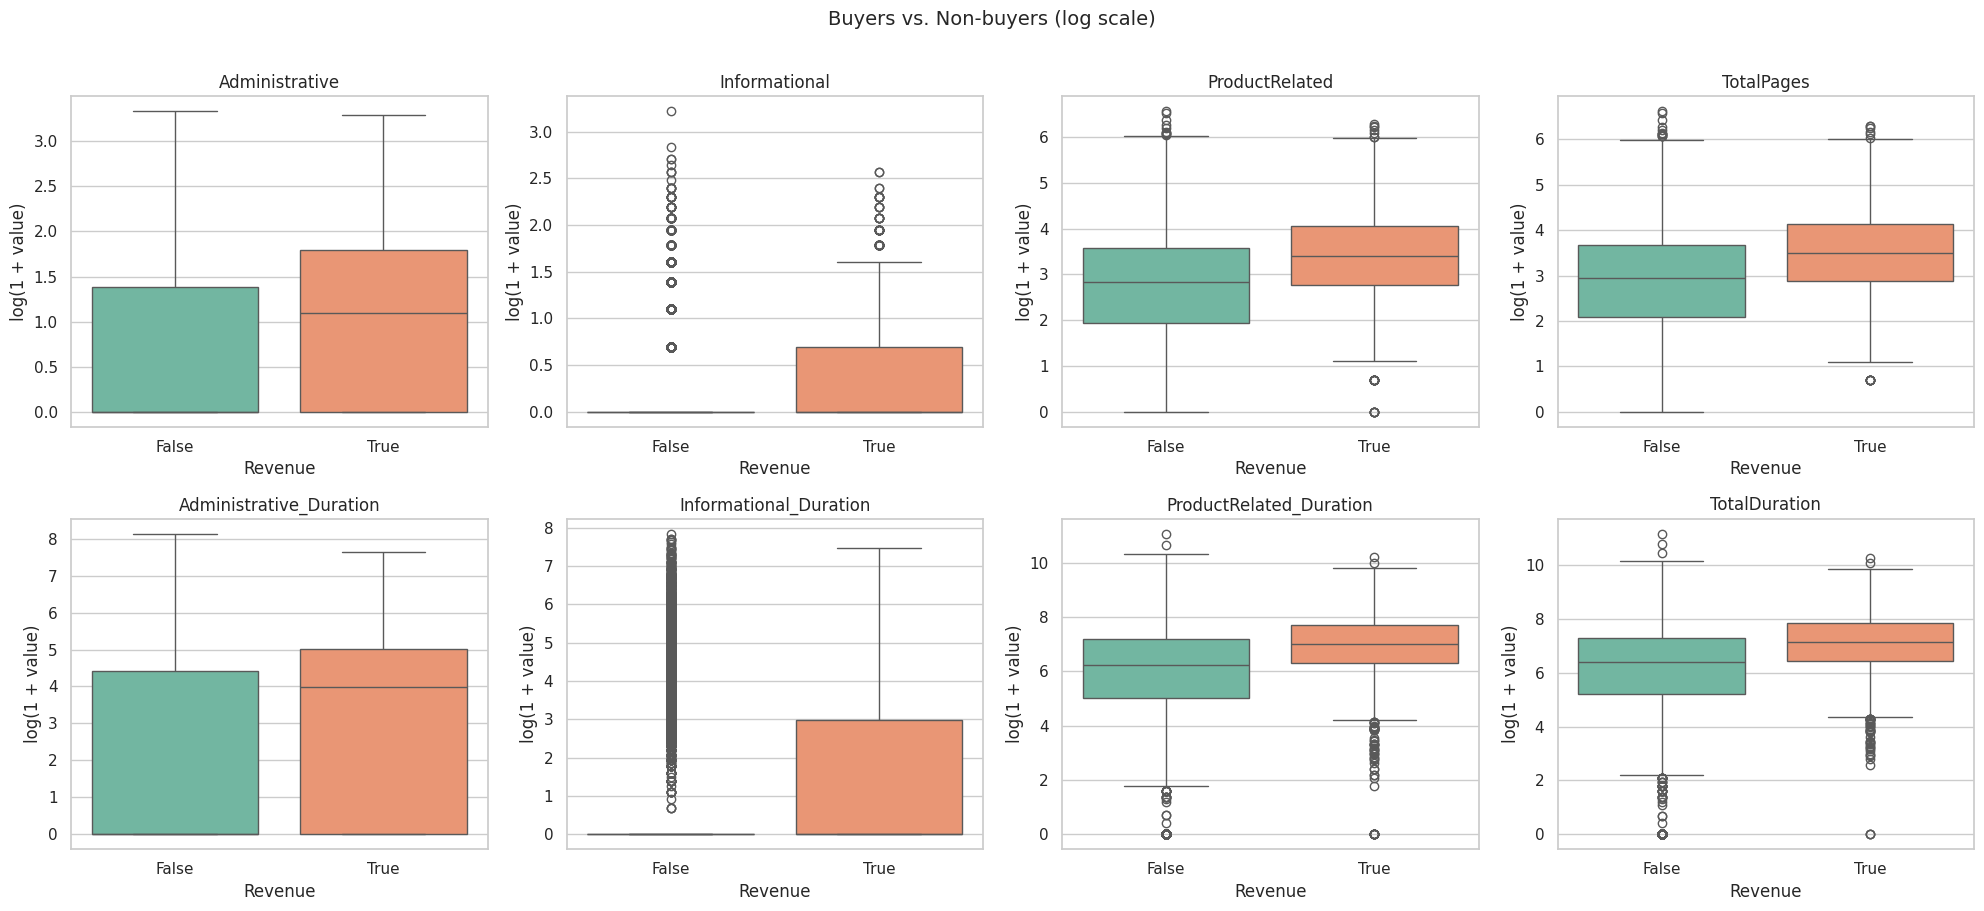


=== Purchase rate by total session duration ===
               sessions   rate
duration_band                 
<=1 min            1418   2.19
1-5 min            2336   6.76
5-15 min           3399  15.62
15-30 min          2423  20.35
30-60 min          1767  22.41
60+ min             987  30.29


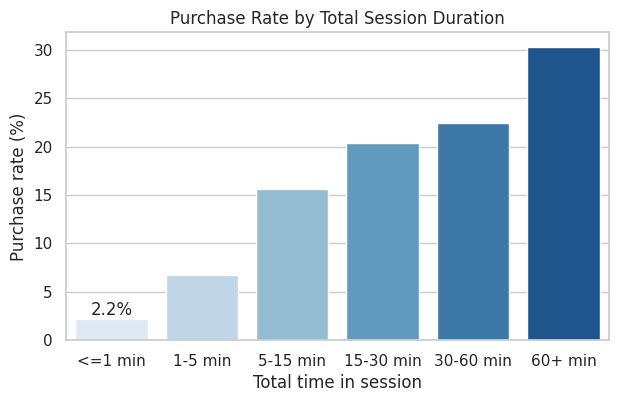

In [8]:
# ============================================
# CELL 7: Bivariate analysis - numeric features vs Revenue
# ============================================

# We make a COPY for exploration so the original df stays untouched.
eda = df.copy()

# Two helpful summary columns, for EDA only:
eda["TotalPages"] = eda["Administrative"] + eda["Informational"] + eda["ProductRelated"]
eda["TotalDuration"] = (eda["Administrative_Duration"]
                        + eda["Informational_Duration"]
                        + eda["ProductRelated_Duration"])

compare_cols = ["Administrative", "Informational", "ProductRelated", "TotalPages",
                "Administrative_Duration", "Informational_Duration",
                "ProductRelated_Duration", "TotalDuration"]

# --- Median and mean for non-buyers (False) vs buyers (True) ---
summary = eda.groupby("Revenue")[compare_cols].agg(["median", "mean"]).T.round(1)
print("=== Non-buyers (False) vs Buyers (True) ===")
print(summary)

# --- Boxplots on a log scale (log1p = log(1 + x), safe for zeros) ---
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flatten(), compare_cols):
    plot_df = pd.DataFrame({"Revenue": eda["Revenue"], "value": np.log1p(eda[col])})
    sns.boxplot(data=plot_df, x="Revenue", y="value", hue="Revenue",
                palette="Set2", legend=False, ax=ax)
    ax.set_title(col)
    ax.set_ylabel("log(1 + value)")
plt.suptitle("Buyers vs. Non-buyers (log scale)", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

# --- Does a longer session mean a higher purchase rate? ---
eda["TotalDuration_min"] = eda["TotalDuration"] / 60
eda["duration_band"] = pd.cut(eda["TotalDuration_min"],
                              bins=[-0.01, 1, 5, 15, 30, 60, np.inf],
                              labels=["<=1 min", "1-5 min", "5-15 min",
                                      "15-30 min", "30-60 min", "60+ min"])
band = eda.groupby("duration_band", observed=True)["Revenue"].agg(
    sessions="count", rate="mean")
band["rate"] = (band["rate"] * 100).round(2)
print("\n=== Purchase rate by total session duration ===")
print(band)

plt.figure(figsize=(7, 4))
ax = sns.barplot(x=band.index.astype(str), y=band["rate"],
                 hue=band.index.astype(str), palette="Blues", legend=False)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Purchase Rate by Total Session Duration")
plt.xlabel("Total time in session")
plt.ylabel("Purchase rate (%)")
plt.show()

=== Purchase rate: PageValues zero vs positive ===
                  sessions  purchases   rate
PageValues_group                            
PageValues = 0        9600        370   3.85
PageValues > 0        2730       1538  56.34

=== PageValues summary by Revenue (sessions with PageValues > 0 only) ===
          count   mean    std   min    25%    50%    75%     max
Revenue                                                         
False    1192.0  17.28  21.35  0.04   5.04  10.46  21.16  246.76
True     1538.0  33.82  36.26  0.07  10.79  22.97  45.56  361.76

=== Purchase rate by bounce_band ===
             sessions   rate
bounce_band                 
0                5518  18.77
0-0.01           2593  21.91
0.01-0.02        1522  12.94
0.02-0.05        1381   6.52
0.05-0.2         1316   1.29

=== Purchase rate by exit_band ===
           sessions   rate
exit_band                 
<=0.01         1914  27.22
0.01-0.02      2928  23.22
0.02-0.05      4669  13.43
0.05-0.1       1707   

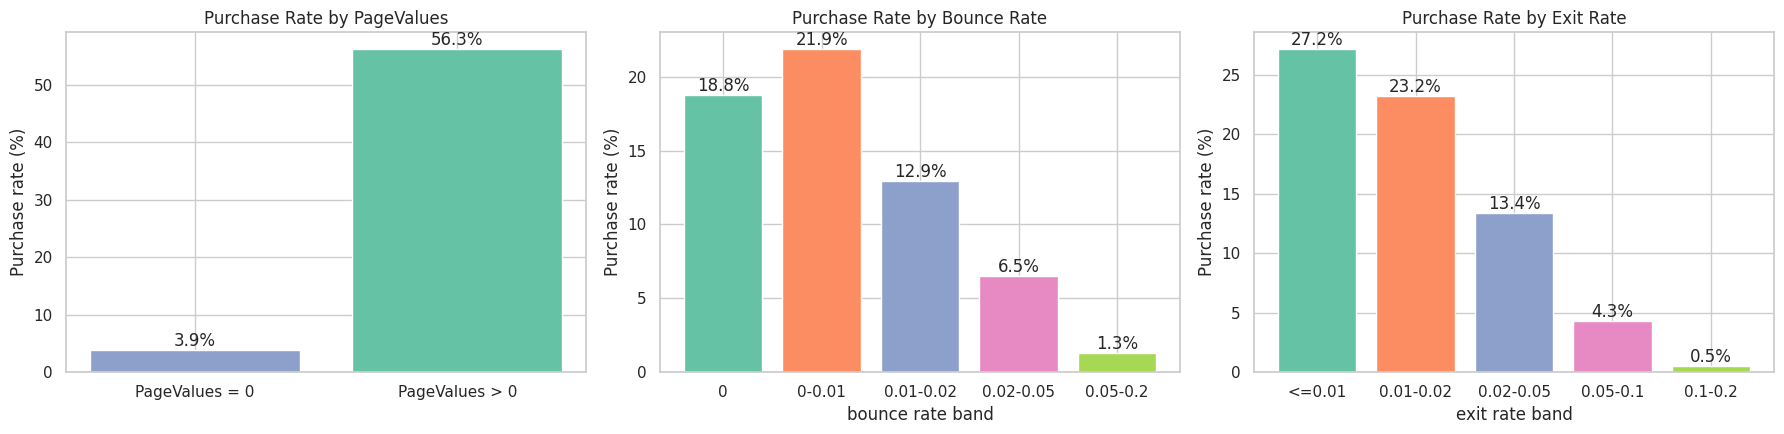

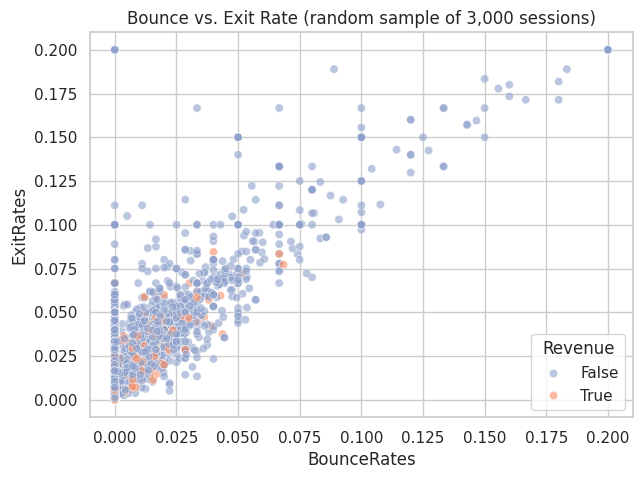

In [9]:
# ============================================
# CELL 8: PageValues, BounceRates, ExitRates vs Revenue
# ============================================

# --- 1. PageValues: zero vs positive ---
eda["PageValues_group"] = np.where(eda["PageValues"] > 0, "PageValues > 0", "PageValues = 0")
pv = eda.groupby("PageValues_group")["Revenue"].agg(sessions="count",
                                                    purchases="sum", rate="mean")
pv["rate"] = (pv["rate"] * 100).round(2)
print("=== Purchase rate: PageValues zero vs positive ===")
print(pv)

print("\n=== PageValues summary by Revenue (sessions with PageValues > 0 only) ===")
print(eda[eda["PageValues"] > 0].groupby("Revenue")["PageValues"]
      .describe().round(2))

# --- 2. BounceRates and ExitRates: purchase rate by band ---
eda["bounce_band"] = pd.cut(eda["BounceRates"],
                            bins=[-0.001, 0, 0.01, 0.02, 0.05, 0.2],
                            labels=["0", "0-0.01", "0.01-0.02", "0.02-0.05", "0.05-0.2"])
eda["exit_band"] = pd.cut(eda["ExitRates"],
                          bins=[-0.001, 0.01, 0.02, 0.05, 0.1, 0.2],
                          labels=["<=0.01", "0.01-0.02", "0.02-0.05", "0.05-0.1", "0.1-0.2"])

for band_col in ["bounce_band", "exit_band"]:
    t = eda.groupby(band_col, observed=True)["Revenue"].agg(sessions="count", rate="mean")
    t["rate"] = (t["rate"] * 100).round(2)
    print(f"\n=== Purchase rate by {band_col} ===")
    print(t)

# --- 3. Plots ---
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].bar(pv.index, pv["rate"], color=["#8da0cb", "#66c2a5"])
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%")
axes[0].set_title("Purchase Rate by PageValues")
axes[0].set_ylabel("Purchase rate (%)")

for ax, band_col, title in zip(axes[1:], ["bounce_band", "exit_band"],
                               ["Purchase Rate by Bounce Rate", "Purchase Rate by Exit Rate"]):
    t = eda.groupby(band_col, observed=True)["Revenue"].mean() * 100
    bars = ax.bar(t.index.astype(str), t.values, color=sns.color_palette("Set2", len(t)))
    ax.bar_label(bars, fmt="%.1f%%")
    ax.set_title(title)
    ax.set_xlabel(band_col.replace("_band", " rate band"))
    ax.set_ylabel("Purchase rate (%)")

plt.tight_layout()
plt.show()

# --- 4. Rates vs Revenue as scatter (a sample, so the plot stays readable) ---
sample = eda.sample(3000, random_state=RANDOM_STATE)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=sample, x="BounceRates", y="ExitRates", hue="Revenue",
                palette={False: "#8da0cb", True: "#fc8d62"}, alpha=0.6)
plt.title("Bounce vs. Exit Rate (random sample of 3,000 sessions)")
plt.show()

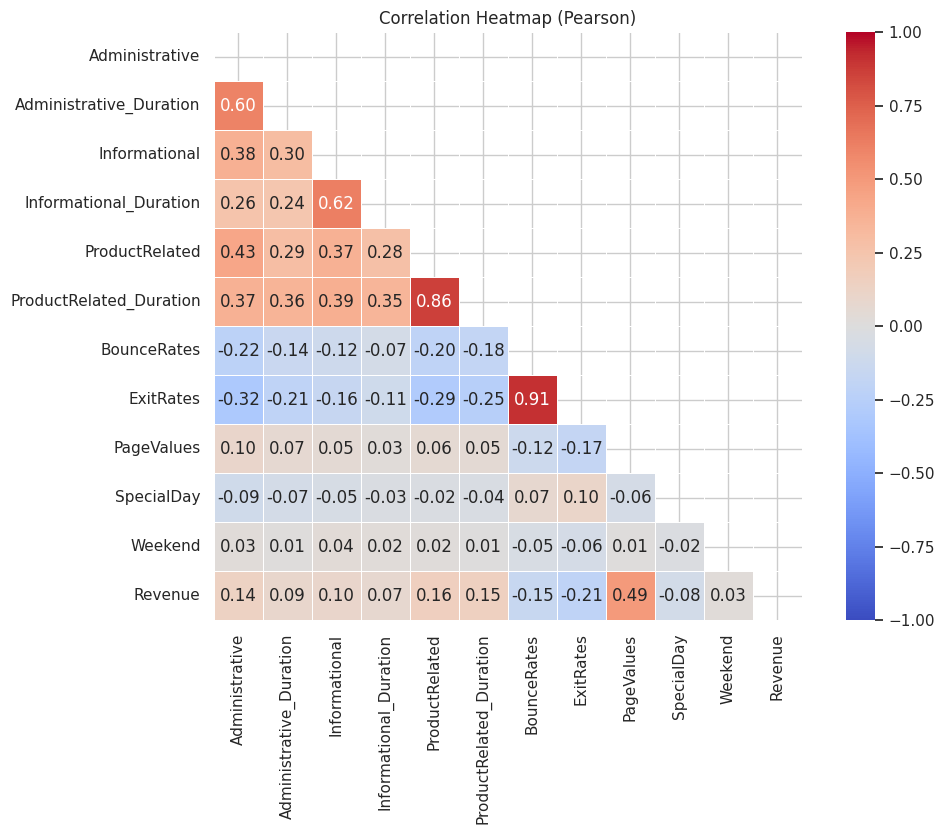

=== TOP 10 FEATURE PAIRS BY |CORRELATION| (Revenue included) ===
     feature_1               feature_2  corr
   BounceRates               ExitRates  0.91
ProductRelated ProductRelated_Duration  0.86
 Informational  Informational_Duration  0.62
Administrative Administrative_Duration  0.60
    PageValues                 Revenue  0.49
Administrative          ProductRelated  0.43
 Informational ProductRelated_Duration  0.39
Administrative           Informational  0.38
 Informational          ProductRelated  0.37
Administrative ProductRelated_Duration  0.37

=== CORRELATION WITH Revenue (sorted by |Spearman|) ===
                         pearson  spearman
PageValues                 0.493     0.626
ExitRates                 -0.207    -0.254
ProductRelated_Duration    0.152     0.217
ProductRelated             0.159     0.199
Administrative             0.139     0.168
Administrative_Duration    0.094     0.164
BounceRates               -0.151    -0.149
Informational              0.095     0.

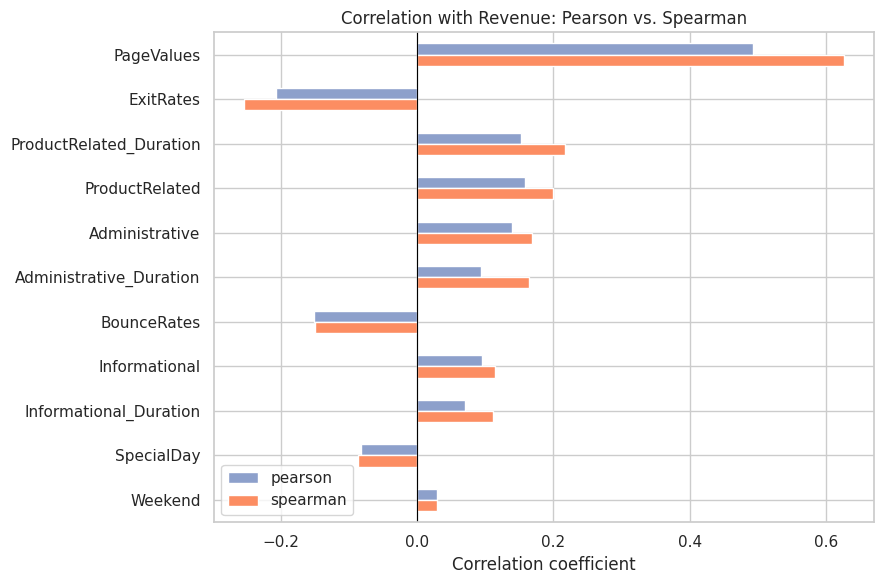

In [10]:
# ============================================
# CELL 9: Correlation analysis
# ============================================

num_cols = ["Administrative", "Administrative_Duration",
            "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration",
            "BounceRates", "ExitRates", "PageValues", "SpecialDay"]

# Work on a copy; turn True/False into 1/0 so they can be correlated
corr_df = df.copy()
corr_df["Revenue"] = corr_df["Revenue"].astype(int)
corr_df["Weekend"] = corr_df["Weekend"].astype(int)
corr_cols = num_cols + ["Weekend", "Revenue"]

# --- 1. Heatmap (Pearson), lower triangle only to avoid duplicate cells ---
pearson = corr_df[corr_cols].corr(method="pearson")
mask = np.triu(np.ones_like(pearson, dtype=bool))

plt.figure(figsize=(11, 8.5))
sns.heatmap(pearson, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, linewidths=0.5, square=True)
plt.title("Correlation Heatmap (Pearson)")
plt.tight_layout()
plt.show()

# --- 2. Strongest feature-to-feature correlations ---
upper = pearson.where(np.triu(np.ones(pearson.shape), k=1).astype(bool))
pairs = upper.stack().reset_index()
pairs.columns = ["feature_1", "feature_2", "corr"]
pairs["abs_corr"] = pairs["corr"].abs()
print("=== TOP 10 FEATURE PAIRS BY |CORRELATION| (Revenue included) ===")
print(pairs.sort_values("abs_corr", ascending=False)
      .head(10)[["feature_1", "feature_2", "corr"]].round(2).to_string(index=False))

# --- 3. Correlation of each feature with Revenue: Pearson vs Spearman ---
spearman = corr_df[corr_cols].corr(method="spearman")
rev_corr = pd.DataFrame({
    "pearson": pearson["Revenue"],
    "spearman": spearman["Revenue"],
}).drop("Revenue").round(3)
rev_corr = rev_corr.reindex(rev_corr["spearman"].abs().sort_values(ascending=False).index)
print("\n=== CORRELATION WITH Revenue (sorted by |Spearman|) ===")
print(rev_corr)

rev_corr.plot(kind="barh", figsize=(9, 6), color=["#8da0cb", "#fc8d62"])
plt.axvline(0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()
plt.title("Correlation with Revenue: Pearson vs. Spearman")
plt.xlabel("Correlation coefficient")
plt.tight_layout()
plt.show()

=== Sessions per Month x VisitorType ===
VisitorType  New_Visitor  Other  Returning_Visitor
Month                                             
Feb                    1      0                183
Mar                  232      0               1675
May                  319      0               3045
June                  30      1                257
Jul                   54      0                378
Aug                   72      0                361
Sep                  108      0                340
Oct                  124      0                425
Nov                  419     22               2557
Dec                  335     62               1330

=== Purchase rate (%) per Month x VisitorType ===
VisitorType  New_Visitor  Other  Returning_Visitor
Month                                             
Feb                  0.0    NaN                1.6
Mar                 15.5    NaN                9.3
May                 27.6    NaN                9.1
June                23.3    0.0          

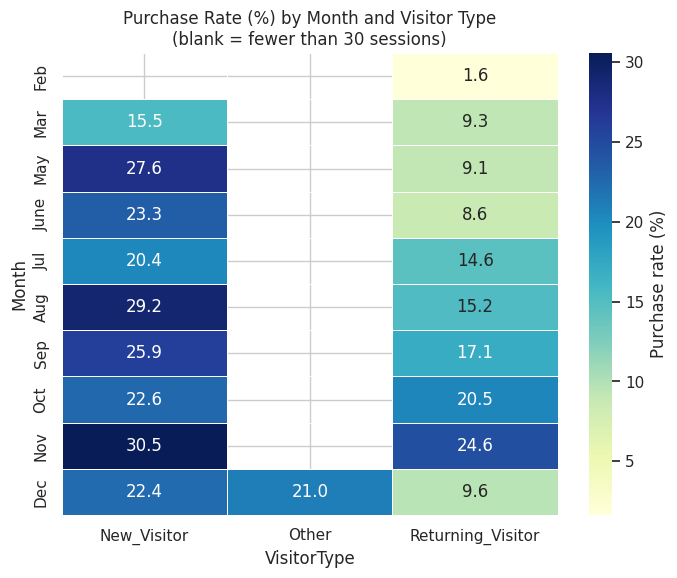

In [11]:
# ============================================
# CELL 10: Purchase rate by Month x VisitorType
# ============================================

all_months = ["Jan", "Feb", "Mar", "Apr", "May", "June",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_order = [m for m in all_months if m in df["Month"].unique()]

tmp = df.assign(Revenue_int=df["Revenue"].astype(int))

rate_piv = (tmp.pivot_table(index="Month", columns="VisitorType",
                            values="Revenue_int", aggfunc="mean") * 100).reindex(month_order)
cnt_piv = tmp.pivot_table(index="Month", columns="VisitorType",
                          values="Revenue_int", aggfunc="count").reindex(month_order)

print("=== Sessions per Month x VisitorType ===")
print(cnt_piv.fillna(0).astype(int))

print("\n=== Purchase rate (%) per Month x VisitorType ===")
print(rate_piv.round(1))

# Hide cells with fewer than 30 sessions: their rates are too noisy to trust
rate_masked = rate_piv.where(cnt_piv >= 30)

plt.figure(figsize=(8, 6))
sns.heatmap(rate_masked, annot=True, fmt=".1f", cmap="YlGnBu",
            linewidths=0.5, cbar_kws={"label": "Purchase rate (%)"})
plt.title("Purchase Rate (%) by Month and Visitor Type\n(blank = fewer than 30 sessions)")
plt.show()

In [12]:
# ============================================
# CELL 11: Remove duplicates, separate X and y, define feature groups
# ============================================

# 1. Remove exact duplicate rows BEFORE splitting
print("Rows before:", len(df))
df_clean = df.drop_duplicates().reset_index(drop=True)
print("Rows after :", len(df_clean))
print("Removed    :", len(df) - len(df_clean))

# 2. Check the target after cleaning
print("\nPurchase rate after cleaning: {:.2f}%".format(df_clean["Revenue"].mean() * 100))
print(df_clean["Revenue"].value_counts())

# 3. Separate inputs (X) from the target (y)
X = df_clean.drop(columns="Revenue")
y = df_clean["Revenue"].astype(int)          # False/True -> 0/1

# 4. Turn the True/False Weekend column into 0/1
X = X.assign(Weekend=X["Weekend"].astype(int))

# 5. Group the 17 features by how they must be treated
skewed_cols = ["Administrative", "Administrative_Duration",
               "Informational", "Informational_Duration",
               "ProductRelated", "ProductRelated_Duration", "PageValues"]
rate_cols   = ["BounceRates", "ExitRates", "SpecialDay"]
cat_cols    = ["Month", "VisitorType", "OperatingSystems",
               "Browser", "Region", "TrafficType"]
binary_cols = ["Weekend"]

# Safety check: every feature must be in exactly one group
listed = skewed_cols + rate_cols + cat_cols + binary_cols
assert sorted(listed) == sorted(X.columns.tolist()), "Feature groups don't match the columns!"
print(f"\nAll {len(listed)} features are assigned to a group.")
print("X shape:", X.shape, "| y shape:", y.shape)

Rows before: 12330
Rows after : 12205
Removed    : 125

Purchase rate after cleaning: 15.63%
Revenue
False    10297
True      1908
Name: count, dtype: int64

All 17 features are assigned to a group.
X shape: (12205, 17) | y shape: (12205,)


In [13]:
# ============================================
# CELL 12: Stratified train/test split
# ============================================
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,            # 80% train, 20% test
    stratify=y,               # keep the purchase rate equal in both sets
    random_state=RANDOM_STATE # same split every time
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

rates = pd.DataFrame({
    "sessions": [len(y), len(y_train), len(y_test)],
    "purchases": [y.sum(), y_train.sum(), y_test.sum()],
    "purchase_rate_%": [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
}, index=["Full data", "Train", "Test"]).round(2)
print("\n", rates)

Train: (9764, 17) | Test: (2441, 17)

            sessions  purchases  purchase_rate_%
Full data     12205       1908            15.63
Train          9764       1526            15.63
Test           2441        382            15.65


In [14]:
# ============================================
# CELL 13: Build the preprocessing recipes (no fitting yet)
# ============================================
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

def build_preprocessor(scale=True, exclude=()):
    """
    scale=True  -> log1p + standardization (for Logistic Regression)
    scale=False -> imputation only for numbers (for tree-based models)
    exclude     -> feature names to leave out, e.g. ("PageValues",)
    """
    skewed = [c for c in skewed_cols if c not in exclude]
    rates  = [c for c in rate_cols   if c not in exclude]
    cats   = [c for c in cat_cols    if c not in exclude]
    bins   = [c for c in binary_cols if c not in exclude]

    if scale:
        skewed_pipe = Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scale", StandardScaler()),
        ])
        rate_pipe = Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ])
    else:
        skewed_pipe = SimpleImputer(strategy="median")
        rate_pipe = SimpleImputer(strategy="median")

    cat_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                 min_frequency=30, sparse_output=False)),
    ])
    bin_pipe = SimpleImputer(strategy="most_frequent")

    return ColumnTransformer(
        transformers=[
            ("skewed", skewed_pipe, skewed),
            ("rates",  rate_pipe,   rates),
            ("cat",    cat_pipe,    cats),
            ("binary", bin_pipe,    bins),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

preprocessor_linear = build_preprocessor(scale=True)    # for Logistic Regression
preprocessor_tree   = build_preprocessor(scale=False)   # for Decision Tree / Random Forest

preprocessor_linear    # displays a diagram of the recipe

ColumnTransformer(transformers=[('skewed',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('log1p',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('scale', StandardScaler())]),
                                 ['Administrative', 'Administrative_Duration',
                                  'Informational', 'Informational_Duration',
                                  'ProductRelated', 'ProductRelated_Duration',
                                  'PageValu...
                                 ['BounceRates', 'ExitRates', 'SpecialDay']),
                                ('cat',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=30,
                                                                sparse_output=False))]),
                                 ['Month', 'VisitorType', 'OperatingSystems',
                                  'Browser', 'Region', 'TrafficType']),
                                ('binary',
                                 SimpleImputer(strategy='most_frequent'),
                                 ['Weekend'])],
                  verbose_feature_names_out=False)

In [15]:
# ============================================
# CELL 14: Fit on TRAIN only, transform both, then verify
# ============================================

# fit_transform on train: LEARNS medians, means, std devs, categories
# transform on test: only APPLIES what was learned from train
Xtr_lin  = preprocessor_linear.fit_transform(X_train)
Xte_lin  = preprocessor_linear.transform(X_test)
Xtr_tree = preprocessor_tree.fit_transform(X_train)
Xte_tree = preprocessor_tree.transform(X_test)

feature_names = preprocessor_linear.get_feature_names_out()

print("Linear recipe : train", Xtr_lin.shape,  "| test", Xte_lin.shape)
print("Tree recipe   : train", Xtr_tree.shape, "| test", Xte_tree.shape)
print("NaNs left (train, test):", np.isnan(Xtr_lin).sum(), np.isnan(Xte_lin).sum())
print("\nFirst 12 output columns:", list(feature_names[:12]))

# --- Which rare categories were grouped together? ---
ohe = preprocessor_linear.named_transformers_["cat"].named_steps["onehot"]
print("\n=== Categories per feature, and which were grouped as 'infrequent' ===")
for name, cats, infreq in zip(cat_cols, ohe.categories_, ohe.infrequent_categories_):
    print(f"{name:18s} {len(cats):2d} categories | grouped: {None if infreq is None else list(infreq)}")

# --- Leakage check: scaling stats come from TRAIN only ---
tr = pd.DataFrame(Xtr_lin, columns=feature_names)
te = pd.DataFrame(Xte_lin, columns=feature_names)
check_cols = ["ProductRelated", "PageValues", "ExitRates"]
print("\n=== Scaled columns: train vs test ===")
print(pd.DataFrame({
    "train_mean": tr[check_cols].mean(), "train_std": tr[check_cols].std(),
    "test_mean":  te[check_cols].mean(), "test_std":  te[check_cols].std(),
}).round(3))

Linear recipe : train (9764, 65) | test (2441, 65)
Tree recipe   : train (9764, 65) | test (2441, 65)
NaNs left (train, test): 0 0

First 12 output columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'PageValues', 'BounceRates', 'ExitRates', 'SpecialDay', 'Month_Aug', 'Month_Dec']

=== Categories per feature, and which were grouped as 'infrequent' ===
Month              10 categories | grouped: None
VisitorType         3 categories | grouped: None
OperatingSystems    8 categories | grouped: [5, 6, 7]
Browser            13 categories | grouped: [9, 11, 12]
Region              9 categories | grouped: None
TrafficType        19 categories | grouped: [14, 16, 17, 18, 19]

=== Scaled columns: train vs test ===
                train_mean  train_std  test_mean  test_std
ProductRelated        -0.0        1.0      0.004     0.985
PageValues            -0.0        1.0      0.006     1.011
ExitRates        

In [16]:
missing = set(df_clean["TrafficType"].unique()) - set(X_train["TrafficType"].unique())
print("TrafficType codes missing from train:", sorted(missing))
print("How often they appear in test:\n",
      X_test["TrafficType"][X_test["TrafficType"].isin(missing)].value_counts())

TrafficType codes missing from train: [np.int64(12)]
How often they appear in test:
 TrafficType
12    1
Name: count, dtype: int64


In [ ]:
# ============================================
# CELL 15: Cross-validation setup + baseline
# ============================================
import warnings
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, f1_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")   # keep the output readable

# 5 stratified folds, shuffled with our fixed seed
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Metrics to compute. zero_division=0 avoids errors when a model predicts no buyers.
scoring = {
    "accuracy":  "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall":    "recall",
    "f1":        make_scorer(f1_score, zero_division=0),
    "roc_auc":   "roc_auc",
}

results = {}   # we store every model's scores here

def evaluate(name, estimator):
    """Cross-validate on TRAINING data only and store mean and std of each metric."""
    scores = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring,
                            return_train_score=True, n_jobs=-1)
    row = {}
    for m in scoring:
        row[m] = scores[f"test_{m}"].mean()           # average over the 5 folds
        row[m + "_std"] = scores[f"test_{m}"].std()   # spread between folds
    row["train_f1"] = scores["train_f1"].mean()       # score on data the model trained on
    results[name] = row
    return row

# --- Baseline: always predict the majority class ("no purchase") ---
evaluate("Baseline (always 'no purchase')", DummyClassifier(strategy="most_frequent"))

print("Baseline cross-validated scores:")
print({k: round(v, 3) for k, v in results["Baseline (always 'no purchase')"].items()
       if not k.endswith("_std") and k != "train_f1"})

In [ ]:
# ============================================
# CELL 16: Cross-validate the three algorithms
# ============================================
import time

models = {
    # Same model without class weights, to see what weighting changes
    "Logistic Regression (unweighted)": Pipeline([
        ("prep", build_preprocessor(scale=True)),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Logistic Regression": Pipeline([
        ("prep", build_preprocessor(scale=True)),
        ("model", LogisticRegression(class_weight="balanced", max_iter=1000,
                                     random_state=RANDOM_STATE)),
    ]),
    # Deliberately UNTUNED: no depth limit, so we can see overfitting
    "Decision Tree": Pipeline([
        ("prep", build_preprocessor(scale=False)),
        ("model", DecisionTreeClassifier(class_weight="balanced",
                                         random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("prep", build_preprocessor(scale=False)),
        ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                         random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
}

for name, pipe in models.items():
    start = time.time()
    evaluate(name, pipe)
    print(f"Done: {name:35s} ({time.time() - start:.0f} s)")

# --- Comparison table (mean over the 5 folds) ---
table = pd.DataFrame(results).T
main_cols = ["accuracy", "precision", "recall", "f1", "roc_auc"]
print("\n=== CROSS-VALIDATED RESULTS (training data only) ===")
display(table[main_cols].round(3))

# --- How much do the folds disagree? (std of recall and F1) ---
print("\n=== FOLD-TO-FOLD SPREAD (standard deviation) ===")
display(table[["recall_std", "f1_std", "roc_auc_std"]].round(3))

In [ ]:
# ============================================
# CELL 17: Visual comparison + overfitting check
# ============================================

# --- 1. Grouped bar chart of the key metrics ---
plot_df = table[["precision", "recall", "f1", "roc_auc"]]
ax = plot_df.plot(kind="bar", figsize=(12, 5), width=0.8, colormap="Set2")
ax.set_title("Cross-validated Model Comparison (training data only)")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_xticklabels(plot_df.index, rotation=20, ha="right")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# --- 2. Overfitting check: score on training folds vs held-out fold ---
gap = pd.DataFrame({
    "F1 on training folds": table["train_f1"],
    "F1 on held-out fold":  table["f1"],
})
gap["gap"] = gap["F1 on training folds"] - gap["F1 on held-out fold"]
print("=== OVERFITTING CHECK (F1) ===")
display(gap.round(3))

In [ ]:
# ============================================
# CELL 18: Same models, same folds, WITHOUT PageValues
# ============================================
import time

NO_PV = ("PageValues",)   # the one feature we leave out

models_no_pv = {
    "Logistic Regression": Pipeline([
        ("prep", build_preprocessor(scale=True, exclude=NO_PV)),
        ("model", LogisticRegression(class_weight="balanced", max_iter=1000,
                                     random_state=RANDOM_STATE)),
    ]),
    "Decision Tree": Pipeline([
        ("prep", build_preprocessor(scale=False, exclude=NO_PV)),
        ("model", DecisionTreeClassifier(class_weight="balanced",
                                         random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("prep", build_preprocessor(scale=False, exclude=NO_PV)),
        ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                         random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
}

# Sanity check: confirm PageValues really is gone from the recipe's output
check = build_preprocessor(scale=True, exclude=NO_PV).fit(X_train)
out_cols = list(check.get_feature_names_out())
print("PageValues in the output columns?", "PageValues" in out_cols)
print("Output columns:", len(out_cols), "(was 65 with PageValues)\n")

for name, pipe in models_no_pv.items():
    start = time.time()
    evaluate(name + " | no PageValues", pipe)
    print(f"Done: {name:22s} ({time.time() - start:.0f} s)")

In [ ]:
# ============================================
# CELL 19: With vs. without PageValues
# ============================================
metrics = ["precision", "recall", "f1", "roc_auc"]
rows = []
for m in ["Logistic Regression", "Decision Tree", "Random Forest"]:
    with_pv = results[m]
    without = results[m + " | no PageValues"]
    for metric in metrics:
        rows.append({
            "model": m, "metric": metric,
            "with PageValues": with_pv[metric],
            "without": without[metric],
            "change": without[metric] - with_pv[metric],
            "fold std (with)": with_pv[metric + "_std"],
        })
cmp_df = pd.DataFrame(rows)

print("=== WITH vs. WITHOUT PageValues (5-fold CV, training data only) ===")
display(cmp_df.round(3))

# --- Chart: F1 and ROC-AUC, with vs. without ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ["f1", "roc_auc"]):
    sub = cmp_df[cmp_df["metric"] == metric].set_index("model")[["with PageValues", "without"]]
    sub.plot(kind="bar", ax=ax, color=["#66c2a5", "#fc8d62"], width=0.75)
    ax.set_title(f"{metric.upper()}: with vs. without PageValues")
    ax.set_ylim(0, 1.0)
    ax.set_xlabel("")
    ax.set_xticklabels(sub.index, rotation=0)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", fontsize=9)
plt.tight_layout()
plt.show()

# --- Overfitting gap without PageValues ---
gap = pd.DataFrame({
    "train F1": {m: results[m + " | no PageValues"]["train_f1"]
                 for m in ["Logistic Regression", "Decision Tree", "Random Forest"]},
    "held-out F1": {m: results[m + " | no PageValues"]["f1"]
                    for m in ["Logistic Regression", "Decision Tree", "Random Forest"]},
})
gap["gap"] = gap["train F1"] - gap["held-out F1"]
print("\n=== OVERFITTING CHECK without PageValues (F1) ===")
display(gap.round(3))

In [ ]:
# ============================================
# CELL 20: Hyperparameter search (TRAINING data only)
# ============================================
import time
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# Record several metrics for every candidate; pick the winner by ROC-AUC
search_scoring = {
    "roc_auc":           "roc_auc",
    "average_precision": "average_precision",
    "f1":                make_scorer(f1_score, zero_division=0),
    "recall":            "recall",
    "precision":         make_scorer(precision_score, zero_division=0),
}

def make_pipe(model, scale, exclude):
    """Fresh preprocessing recipe + model, so CV never leaks."""
    return Pipeline([("prep", build_preprocessor(scale=scale, exclude=exclude)),
                     ("model", model)])

feature_sets = {"with PageValues": (), "no PageValues": ("PageValues",)}
searches = {}    # (model name, feature set) -> fitted search object

for fs_name, excl in feature_sets.items():

    # --- Logistic Regression: small grid, try every combination ---
    lr_search = GridSearchCV(
        make_pipe(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                  scale=True, exclude=excl),
        param_grid={"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
                    "model__class_weight": [None, "balanced"]},
        scoring=search_scoring, refit="roc_auc", cv=cv, n_jobs=-1)

    # --- Decision Tree: depth limit is the key fix for overfitting ---
    dt_search = GridSearchCV(
        make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE),
                  scale=False, exclude=excl),
        param_grid={"model__max_depth": [3, 4, 5, 6, 8, 10],
                    "model__min_samples_leaf": [5, 10, 20, 50],
                    "model__class_weight": ["balanced"]},
        scoring=search_scoring, refit="roc_auc", cv=cv, n_jobs=-1)

    # --- Random Forest: 20 random combinations out of 270 ---
    rf_search = RandomizedSearchCV(
        make_pipe(RandomForestClassifier(n_estimators=200, n_jobs=1,
                                         random_state=RANDOM_STATE),
                  scale=False, exclude=excl),
        param_distributions={
            "model__max_depth": [4, 6, 8, 10, 14, None],
            "model__min_samples_leaf": [1, 3, 5, 10, 20],
            "model__max_features": ["sqrt", 0.3, 0.5],
            "model__class_weight": ["balanced", "balanced_subsample", None]},
        n_iter=20, scoring=search_scoring, refit="roc_auc", cv=cv,
        n_jobs=-1, random_state=RANDOM_STATE)

    for model_name, s in [("Logistic Regression", lr_search),
                          ("Decision Tree", dt_search),
                          ("Random Forest", rf_search)]:
        start = time.time()
        s.fit(X_train, y_train)          # uses ONLY the training data
        searches[(model_name, fs_name)] = s
        print(f"Done: {model_name:20s} | {fs_name:16s} | "
              f"best CV ROC-AUC = {s.best_score_:.3f} | {time.time() - start:.0f} s")

In [ ]:
# ============================================
# CELL 21: What did tuning change?
# ============================================
untuned = {  # ROC-AUC from Part A / Part B (same folds, same metric)
    ("Logistic Regression", "with PageValues"): results["Logistic Regression"]["roc_auc"],
    ("Decision Tree",       "with PageValues"): results["Decision Tree"]["roc_auc"],
    ("Random Forest",       "with PageValues"): results["Random Forest"]["roc_auc"],
    ("Logistic Regression", "no PageValues"):   results["Logistic Regression | no PageValues"]["roc_auc"],
    ("Decision Tree",       "no PageValues"):   results["Decision Tree | no PageValues"]["roc_auc"],
    ("Random Forest",       "no PageValues"):   results["Random Forest | no PageValues"]["roc_auc"],
}

rows = []
for (model_name, fs_name), s in searches.items():
    i = s.best_index_
    rows.append({
        "model": model_name, "features": fs_name,
        "untuned AUC": untuned[(model_name, fs_name)],
        "tuned AUC": s.cv_results_["mean_test_roc_auc"][i],
        "AUC fold std": s.cv_results_["std_test_roc_auc"][i],
        "avg precision": s.cv_results_["mean_test_average_precision"][i],
        "F1 @0.5": s.cv_results_["mean_test_f1"][i],
        "recall @0.5": s.cv_results_["mean_test_recall"][i],
        "precision @0.5": s.cv_results_["mean_test_precision"][i],
    })
summary = pd.DataFrame(rows)
summary["AUC change"] = summary["tuned AUC"] - summary["untuned AUC"]
summary = summary.sort_values(["features", "tuned AUC"], ascending=[False, False])
print("=== TUNED MODELS (5-fold CV on training data; F1/recall/precision use the default 0.5 cutoff) ===")
display(summary.round(3).reset_index(drop=True))

print("\n=== BEST SETTINGS FOUND ===")
for (model_name, fs_name), s in searches.items():
    clean = {k.replace("model__", ""): v for k, v in s.best_params_.items()}
    print(f"{model_name:20s} | {fs_name:16s} | {clean}")

In [ ]:
# ============================================
# CELL 22: Top Random Forest candidates (is the best one clearly better?)
# ============================================
cols = ["mean_test_roc_auc", "std_test_roc_auc", "mean_test_recall", "mean_test_f1",
        "param_model__max_depth", "param_model__min_samples_leaf",
        "param_model__max_features", "param_model__class_weight"]
for fs_name in feature_sets:
    cvr = pd.DataFrame(searches[("Random Forest", fs_name)].cv_results_)
    print(f"\n=== Top 5 Random Forest candidates ({fs_name}) ===")
    display(cvr.sort_values("rank_test_roc_auc")[cols].head(5).round(3)
            .rename(columns=lambda c: c.replace("param_model__", "").replace("_test_", " ")))

In [ ]:
# ============================================
# CELL 23: Out-of-fold predicted probabilities (TRAINING data only)
# ============================================
import time
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score

oof = {}   # (model, feature set) -> probability of purchase for every training row

for (model_name, fs_name), s in searches.items():
    start = time.time()
    proba = cross_val_predict(
        s.best_estimator_, X_train, y_train, cv=cv,   # same 5 folds as before
        method="predict_proba", n_jobs=-1)[:, 1]      # column 1 = P(purchase)
    oof[(model_name, fs_name)] = proba

    # Sanity checks: one value per training row, and AUC close to the CV result
    assert len(proba) == len(y_train)
    print(f"{model_name:20s} | {fs_name:16s} | pooled OOF AUC = {roc_auc_score(y_train, proba):.3f} "
          f"(search CV mean = {s.best_score_:.3f}) | {time.time() - start:.0f} s")

In [ ]:
# ============================================
# CELL 24: Cutoff curves + best cutoff per scenario
# ============================================
from sklearn.metrics import precision_recall_curve

def best_threshold(y_true, proba, beta=1.0):
    """Cutoff that maximizes F-beta, with its precision and recall."""
    prec, rec, thr = precision_recall_curve(y_true, proba)
    prec, rec = prec[:-1], rec[:-1]                  # align with thresholds
    b2 = beta ** 2
    denom = b2 * prec + rec
    fb = np.where(denom == 0, 0, (1 + b2) * prec * rec / np.where(denom == 0, 1, denom))
    i = int(np.argmax(fb))
    return thr[i], prec[i], rec[i], fb[i]

order = ["Logistic Regression", "Decision Tree", "Random Forest"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey=True)
for r, fs_name in enumerate(["with PageValues", "no PageValues"]):
    for c, model_name in enumerate(order):
        ax = axes[r, c]
        proba = oof[(model_name, fs_name)]
        prec, rec, thr = precision_recall_curve(y_train, proba)
        prec, rec = prec[:-1], rec[:-1]
        f1 = 2 * prec * rec / np.where(prec + rec == 0, 1, prec + rec)
        ax.plot(thr, prec, label="precision", color="#66c2a5")
        ax.plot(thr, rec,  label="recall",    color="#8da0cb")
        ax.plot(thr, f1,   label="F1",        color="#fc8d62", linewidth=2)
        t_best = thr[int(np.argmax(f1))]
        ax.axvline(t_best, color="grey", linestyle="--", label=f"best F1 cutoff = {t_best:.2f}")
        ax.axvline(0.5, color="black", linestyle=":", linewidth=1, label="default 0.5")
        ax.set_title(f"{model_name} | {fs_name}")
        ax.set_xlabel("Cutoff (flag visitor if P(purchase) >= cutoff)")
        ax.legend(fontsize=8, loc="center left")
        if c == 0:
            ax.set_ylabel("Score")
plt.tight_layout()
plt.show()

# --- Best cutoff for each business scenario ---
scenarios = {"A: cheap action (F2)": 2.0, "B: balanced (F1)": 1.0, "C: costly action (F0.5)": 0.5}
rows = []
for (model_name, fs_name), proba in oof.items():
    for sc_name, beta in scenarios.items():
        t, p, rc, fb = best_threshold(y_train, proba, beta)
        rows.append({"features": fs_name, "model": model_name, "scenario": sc_name,
                     "cutoff": t, "precision": p, "recall": rc,
                     "% of visitors flagged": (proba >= t).mean() * 100})
sc_table = pd.DataFrame(rows).sort_values(["features", "scenario", "model"],
                                          ascending=[False, True, True])
print("=== BEST CUTOFF PER SCENARIO (out-of-fold predictions on training data) ===")
display(sc_table.round(3).reset_index(drop=True))

In [ ]:
# ============================================
# CELL 25: Models on equal footing
# ============================================
def precision_at_recall(y_true, proba, target):
    prec, rec, thr = precision_recall_curve(y_true, proba)
    prec, rec = prec[:-1], rec[:-1]
    ok = np.where(rec >= target)[0]
    i = ok[-1]                                      # highest cutoff that still reaches the target
    return prec[i], (proba >= thr[i]).mean() * 100

def recall_at_precision(y_true, proba, target):
    prec, rec, _ = precision_recall_curve(y_true, proba)
    ok = prec[:-1] >= target
    return rec[:-1][ok].max() if ok.any() else 0.0

base_rate = y_train.mean()
rows = []
for (model_name, fs_name), proba in oof.items():
    p80, flagged80 = precision_at_recall(y_train, proba, 0.80)
    rows.append({
        "features": fs_name, "model": model_name,
        "avg precision": average_precision_score(y_train, proba),
        "precision @80% recall": p80,
        "lift @80% recall": p80 / base_rate,
        "% flagged @80% recall": flagged80,
        "recall @50% precision": recall_at_precision(y_train, proba, 0.50),
    })
eq = pd.DataFrame(rows).sort_values(["features", "precision @80% recall"],
                                    ascending=[False, False])
print(f"Base purchase rate in training data: {base_rate:.3f}  (a no-skill model has precision = {base_rate:.3f})")
display(eq.round(3).reset_index(drop=True))

# --- Precision-recall curves overlaid ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
colors = {"Logistic Regression": "#66c2a5", "Decision Tree": "#fc8d62", "Random Forest": "#8da0cb"}
for ax, fs_name in zip(axes, ["with PageValues", "no PageValues"]):
    for model_name in order:
        prec, rec, _ = precision_recall_curve(y_train, oof[(model_name, fs_name)])
        ax.plot(rec, prec, label=model_name, color=colors[model_name], linewidth=2)
    ax.axhline(base_rate, color="grey", linestyle="--", label=f"no skill ({base_rate:.2f})")
    ax.set_title(f"Precision-Recall curves | {fs_name}")
    ax.set_xlabel("Recall (share of buyers caught)")
    ax.set_ylabel("Precision (share of flagged visitors who buy)")
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# CELL 26 (optional): Paired bootstrap of model gaps in average precision
# ============================================
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_train.to_numpy()
n = len(y_arr)

for fs_name in ["with PageValues", "no PageValues"]:
    for rival in ["Logistic Regression", "Decision Tree"]:
        pa, pb = oof[("Random Forest", fs_name)], oof[(rival, fs_name)]
        diffs = []
        for _ in range(500):
            idx = rng.integers(0, n, n)          # resample rows with replacement
            diffs.append(average_precision_score(y_arr[idx], pa[idx])
                         - average_precision_score(y_arr[idx], pb[idx]))
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        print(f"{fs_name:16s} | Forest minus {rival:20s}: "
              f"{np.mean(diffs):+.3f}  (95% range {lo:+.3f} to {hi:+.3f})")

In [ ]:
# ============================================
# CELL 27: Lock final models and cutoffs (TRAINING data only; test not touched)
# ============================================
feature_sets_list = ["with PageValues", "no PageValues"]

# The tuned Random Forest, already re-fitted on the full TRAINING set by the search
final_models = {fs: searches[("Random Forest", fs)].best_estimator_
                for fs in feature_sets_list}

scenarios = {"A: cheap action (F2)": 2.0,
             "B: balanced (F1)": 1.0,
             "C: costly action (F0.5)": 0.5}

# Cutoffs come from out-of-fold predictions on the training set
cutoffs = {}
for fs in feature_sets_list:
    for sc, beta in scenarios.items():
        t, _, _, _ = best_threshold(y_train, oof[("Random Forest", fs)], beta)
        cutoffs[(fs, sc)] = float(t)

print("LOCKED CUTOFFS (flag a visitor if P(purchase) >= cutoff)")
print(pd.DataFrame({fs: {sc: round(cutoffs[(fs, sc)], 3) for sc in scenarios}
                    for fs in feature_sets_list}))

In [ ]:
# ============================================
# CELL 28: Final evaluation on the TEST set (run this ONCE)
# ============================================
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, roc_curve)

test_proba = {fs: m.predict_proba(X_test)[:, 1] for fs, m in final_models.items()}

# --- Ranking quality (cutoff-free) ---
print("=== RANKING QUALITY ON THE TEST SET ===")
print(f"Test set: {len(y_test)} sessions, {int(y_test.sum())} buyers "
      f"({y_test.mean()*100:.2f}%) | 'always no purchase' accuracy = {(1 - y_test.mean()):.3f}")
for fs in feature_sets_list:
    p = test_proba[fs]
    print(f"{fs:16s} | ROC-AUC = {roc_auc_score(y_test, p):.3f} "
          f"| average precision = {average_precision_score(y_test, p):.3f}")

# --- Metrics at each scenario's locked cutoff ---
rows = []
for fs in feature_sets_list:
    p = test_proba[fs]
    oof_p = oof[("Random Forest", fs)]
    for sc in scenarios:
        t = cutoffs[(fs, sc)]
        pred = (p >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        oof_pred = (oof_p >= t).astype(int)
        rows.append({
            "features": fs, "scenario": sc, "cutoff": round(t, 3),
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "TP": tp, "FN": fn, "FP": fp, "TN": tn,
            "% flagged": pred.mean() * 100,
            "CV precision": precision_score(y_train, oof_pred),
            "CV recall": recall_score(y_train, oof_pred),
        })
final = pd.DataFrame(rows)
print("\n=== TEST RESULTS AT THE LOCKED CUTOFFS (CV = expectation from training out-of-fold) ===")
display(final.round(3))

# --- Confusion matrices: 2 rows (feature set) x 3 columns (scenario) ---
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for r, fs in enumerate(feature_sets_list):
    for c, sc in enumerate(scenarios):
        t = cutoffs[(fs, sc)]
        cm = confusion_matrix(y_test, (test_proba[fs] >= t).astype(int))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[r, c],
                    xticklabels=["No purchase", "Purchase"],
                    yticklabels=["No purchase", "Purchase"])
        axes[r, c].set_title(f"{fs}\n{sc} | cutoff {t:.2f}")
        axes[r, c].set_xlabel("Predicted")
        axes[r, c].set_ylabel("Actual")
plt.tight_layout()
plt.show()

# --- ROC and Precision-Recall curves on the test set ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cols = {"with PageValues": "#66c2a5", "no PageValues": "#fc8d62"}
for fs in feature_sets_list:
    fpr, tpr, _ = roc_curve(y_test, test_proba[fs])
    axes[0].plot(fpr, tpr, color=cols[fs], linewidth=2,
                 label=f"{fs} (AUC = {roc_auc_score(y_test, test_proba[fs]):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, test_proba[fs])
    axes[1].plot(rec, prec, color=cols[fs], linewidth=2, label=fs)
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="coin flip")
axes[0].set_title("ROC Curve (test set)")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].legend()
axes[1].axhline(y_test.mean(), color="grey", linestyle="--", label=f"no skill ({y_test.mean():.2f})")
axes[1].set_title("Precision-Recall Curve (test set)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# CELL 29: Confidence ranges + error analysis (test set; nothing is re-tuned)
# ============================================
rng = np.random.default_rng(RANDOM_STATE)
y_t = y_test.to_numpy()

# --- 1. Bootstrap 95% ranges at the headline scenario (B) ---
print("=== 95% RANGES (1,000 bootstrap resamples of the test set; scenario B cutoff) ===")
for fs in feature_sets_list:
    p = test_proba[fs]
    t = cutoffs[(fs, "B: balanced (F1)")]
    stats = {"ROC-AUC": [], "precision": [], "recall": [], "F1": []}
    for _ in range(1000):
        idx = rng.integers(0, len(y_t), len(y_t))
        yt, pp = y_t[idx], p[idx]
        pred = (pp >= t).astype(int)
        stats["ROC-AUC"].append(roc_auc_score(yt, pp))
        stats["precision"].append(precision_score(yt, pred, zero_division=0))
        stats["recall"].append(recall_score(yt, pred))
        stats["F1"].append(f1_score(yt, pred))
    print(f"\n{fs}")
    for k, v in stats.items():
        lo, hi = np.percentile(v, [2.5, 97.5])
        print(f"  {k:10s} {np.mean(v):.3f}   (95% range {lo:.3f} to {hi:.3f})")

# --- 2. Error analysis at scenario B ---
key_cols = ["PageValues", "ExitRates", "BounceRates", "ProductRelated",
            "ProductRelated_Duration", "Administrative"]
for fs in feature_sets_list:
    p = test_proba[fs]
    t = cutoffs[(fs, "B: balanced (F1)")]
    pred = (p >= t).astype(int)
    actual = y_test.to_numpy()
    ea = X_test.copy()
    ea["outcome"] = np.select(
    [(actual == 1) & (pred == 1), (actual == 1) & (pred == 0),
     (actual == 0) & (pred == 1), (actual == 0) & (pred == 0)],
    ["TP (caught buyer)", "FN (missed buyer)",
     "FP (false alarm)", "TN (correctly ignored)"],
    default="Unknown"
)
    print(f"\n\n===== ERROR ANALYSIS | {fs} | scenario B =====")
    print("\nMedian feature values by outcome:")
    display(ea.groupby("outcome")[key_cols].median().round(3))
    print("Session counts:", ea["outcome"].value_counts().to_dict())

    print("\nShare of each outcome group that are NEW visitors (%):")
    print((ea.assign(new=ea["VisitorType"].eq("New_Visitor"))
             .groupby("outcome")["new"].mean() * 100).round(1))

    miss_rate = (ea[actual == 1].assign(missed=lambda d: d["outcome"].str.startswith("FN"))
                 .groupby("Month")["missed"].agg(["sum", "count"]))
    miss_rate["miss rate %"] = (miss_rate["sum"] / miss_rate["count"] * 100).round(1)
    print("\nMissed-buyer rate by month (actual buyers only):")
    print(miss_rate.rename(columns={"sum": "missed", "count": "buyers"}))

In [ ]:
# ============================================
# CELL 30: Phase 6 - drivers, interpretation and business actions (all in one)
# Descriptive only: nothing is re-tuned or re-chosen.
# ============================================
from sklearn.inspection import permutation_importance

y_arr = y_test.to_numpy()

# ---------- 1. Permutation importance of the final forests ----------
imp = {}
for fs in feature_sets_list:
    r = permutation_importance(final_models[fs], X_test, y_test, scoring="roc_auc",
                               n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    d = pd.DataFrame({"feature": X_test.columns, "AUC drop": r.importances_mean, "std": r.importances_std})
    if fs == "no PageValues":
        d = d[d["feature"] != "PageValues"]          # that model never saw it
    imp[fs] = d.sort_values("AUC drop", ascending=False).reset_index(drop=True)
    print(f"\n=== 1. TOP 10 FEATURES | {fs} (drop in test ROC-AUC when shuffled) ===")
    display(imp[fs].head(10).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, fs in zip(axes, feature_sets_list):
    d = imp[fs].head(10).iloc[::-1]
    ax.barh(d["feature"], d["AUC drop"], xerr=d["std"],
            color="#66c2a5" if fs == "with PageValues" else "#fc8d62")
    ax.set_title(f"Permutation importance | {fs}")
    ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.tight_layout(); plt.show()

# ---------- 2. Logistic Regression coefficients ----------
for fs in feature_sets_list:
    pipe = searches[("Logistic Regression", fs)].best_estimator_
    names = pipe.named_steps["prep"].get_feature_names_out()
    c = pd.DataFrame({"feature": names, "coefficient": pipe.named_steps["model"].coef_[0]})
    c["odds ratio"] = np.exp(c["coefficient"])
    c = c.sort_values("coefficient", ascending=False)
    s = {k.replace("model__", ""): v for k, v in searches[("Logistic Regression", fs)].best_params_.items()}
    print(f"\n=== 2. LOGISTIC REGRESSION | {fs} | settings {s} ===")
    print("Strongest pushes TOWARD purchase:")
    display(c.head(8).round(3).reset_index(drop=True))
    print("Strongest pushes AWAY from purchase:")
    display(c.tail(8).iloc[::-1].round(3).reset_index(drop=True))

# ---------- 3. Score deciles (test set) ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, fs in zip(axes, feature_sets_list):
    p = test_proba[fs]
    dec = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False)   # 0 = lowest scores
    tbl = (pd.DataFrame({"decile": dec.values, "bought": y_arr})
             .groupby("decile")["bought"].agg(sessions="count", buyers="sum", rate="mean"))
    tbl["rate %"] = (tbl["rate"] * 100).round(1)
    tbl = tbl.drop(columns="rate").iloc[::-1]                            # highest-scored first
    tbl.index = ["Top 10%"] + [f"{10 * i}-{10 * (i + 1)}%" for i in range(1, 10)]
    tbl["cumulative % of all buyers"] = (tbl["buyers"].cumsum() / tbl["buyers"].sum() * 100).round(1)
    print(f"\n=== 3. {fs}: visitors sorted by score, 10 equal groups (test set) ===")
    display(tbl)
    ax.bar(range(1, 11), tbl["rate %"].values, color="#66c2a5" if fs == "with PageValues" else "#fc8d62")
    ax.axhline(y_arr.mean() * 100, color="grey", linestyle="--", label=f"average ({y_arr.mean()*100:.1f}%)")
    ax.set_title(f"Actual purchase rate by score group | {fs}")
    ax.set_xlabel("Score group (1 = highest-scored 10% of visitors)")
    ax.set_ylabel("Share who actually bought (%)")
    ax.set_xticks(range(1, 11)); ax.legend()
plt.tight_layout(); plt.show()

# ---------- 4. Action table at the locked cutoffs ----------
rows = []
for fs in feature_sets_list:
    p = test_proba[fs]
    for sc in scenarios:
        flag = p >= cutoffs[(fs, sc)]
        n_flag = int(flag.sum())
        tp = int((flag & (y_arr == 1)).sum())
        rows.append({"features": fs, "scenario": sc,
                     "triggers per 1,000 visitors": round(n_flag / len(p) * 1000),
                     "real buyers per 100 triggers": round(tp / n_flag * 100, 1),
                     "wasted triggers per 100": round((n_flag - tp) / n_flag * 100, 1),
                     "% of all buyers reached": round(tp / y_arr.sum() * 100, 1)})
print("\n=== 4. WHAT EACH SCENARIO MEANS IN PRACTICE (test set, locked cutoffs) ===")
display(pd.DataFrame(rows))

# ---------- 5. Discount sensitivity (ILLUSTRATIVE ASSUMPTIONS, not measured) ----------
# Order value = 1. margin = profit share of an order BEFORE any discount.
# d = discount given (share of order value). r = share of flagged NON-buyers who
# convert BECAUSE of the discount. Flagged real buyers get the discount too (pure cost).
MARGIN = 0.30
def net_per_100_triggers(prec100, d, r):
    buyers, nonbuyers = prec100, 100 - prec100
    return nonbuyers * r * (MARGIN - d) - buyers * d      # in units of one order's value

print(f"\n=== 5. DISCOUNT SENSITIVITY (net value per 100 triggers, order value = 1, margin = {MARGIN:.0%}) ===")
print("ASSUMPTIONS, not data: d = discount size, r = share of flagged non-buyers the discount wins over.")
for fs in feature_sets_list:
    prec100 = [x["real buyers per 100 triggers"] for x in rows
               if x["features"] == fs and x["scenario"].startswith("B")][0]
    grid = pd.DataFrame({f"r = {r:.0%}": {f"d = {d:.0%}": round(net_per_100_triggers(prec100, d, r), 2)
                                          for d in [0.05, 0.10, 0.20]}
                         for r in [0.02, 0.05, 0.10]})
    print(f"\n{fs}, scenario B ({prec100:.1f} real buyers per 100 triggers):")
    display(grid)

# ---------- 6. Flagged visitors by visitor type (scenario B) ----------
for fs in feature_sets_list:
    flag = test_proba[fs] >= cutoffs[(fs, "B: balanced (F1)")]
    d = pd.DataFrame({"VisitorType": X_test["VisitorType"].to_numpy(), "flagged": flag, "bought": y_arr})
    f = d[d["flagged"]].groupby("VisitorType")["bought"].agg(flagged="count", bought="sum", precision="mean").round(3)
    print(f"\n=== 6. {fs}, scenario B: flagged visitors by type (under ~50 flagged = unreliable) ===")
    print(f)

In [ ]:
# ============================================
# CELL 31 (optional): Retrain the forest WITHOUT Month (training CV only)
# ============================================
from sklearn.base import clone

rows = []
for fs, excl in [("with PageValues", ()), ("no PageValues", ("PageValues",))]:
    best_rf = searches[("Random Forest", fs)].best_estimator_
    for label, ex in [("with Month", excl), ("without Month", excl + ("Month",))]:
        pipe = clone(best_rf)                                   # unfitted copy, same tuned settings
        pipe.set_params(prep=build_preprocessor(scale=False, exclude=ex))
        sc = cross_validate(pipe, X_train, y_train, cv=cv, n_jobs=-1,
                            scoring={"roc_auc": "roc_auc", "average_precision": "average_precision"})
        rows.append({"features": fs, "forest": label,
                     "ROC-AUC": sc["test_roc_auc"].mean(), "AUC std": sc["test_roc_auc"].std(),
                     "avg precision": sc["test_average_precision"].mean()})
display(pd.DataFrame(rows).round(3))

In [ ]:
# ============================================
# CELL 32: Phase 7 - save, reload and test the final model bundle
# The models are saved exactly as evaluated: nothing is re-tuned or re-fitted.
# ============================================
import os, sys, json, platform, datetime, subprocess, shutil
import joblib, sklearn
from sklearn.metrics import roc_curve

OUT = "purchase-intent-predictor"
os.makedirs(f"{OUT}/data", exist_ok=True)

# ---------- 1. Facts the app needs, taken from TRAINING data ----------
month_calendar = ["Jan", "Feb", "Mar", "Apr", "May", "June",
                  "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
allowed_values = {
    "Month": [m for m in month_calendar if m in set(X_train["Month"])],
    "VisitorType": sorted(X_train["VisitorType"].unique().tolist()),
}
for col in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
    allowed_values[col] = sorted(int(v) for v in X_train[col].unique())

numeric_cols = ["Administrative", "Administrative_Duration", "Informational",
                "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
                "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
numeric_ranges = {c: (float(X_train[c].min()), float(X_train[c].max())) for c in numeric_cols}

# ---------- 2. Test-set evidence for the Model Information page ----------
roc_points, deciles = {}, {}
for fs in feature_sets_list:
    fpr, tpr, _ = roc_curve(y_test, test_proba[fs])
    roc_points[fs] = {"fpr": fpr, "tpr": tpr}
    dec = pd.qcut(pd.Series(test_proba[fs]).rank(method="first"), 10, labels=False)
    t = (pd.DataFrame({"decile": dec.values, "bought": y_test.to_numpy()})
           .groupby("decile")["bought"].agg(sessions="count", buyers="sum").iloc[::-1])
    t["purchase_rate_pct"] = (t["buyers"] / t["sessions"] * 100).round(1)
    t.index = range(1, 11)                      # 1 = highest-scored 10% of visitors
    deciles[fs] = t

# ---------- 3. Build and save the bundle ----------
bundle = {
    "models": {fs: final_models[fs] for fs in feature_sets_list},
    "cutoffs": {fs: {sc: float(cutoffs[(fs, sc)]) for sc in scenarios}
                for fs in feature_sets_list},
    "scenario_names": list(scenarios),
    "feature_columns": X_train.columns.tolist(),
    "allowed_values": allowed_values,
    "numeric_ranges": numeric_ranges,
    "test_metrics": final.to_dict("records"),
    "test_auc": {fs: float(roc_auc_score(y_test, test_proba[fs])) for fs in feature_sets_list},
    "test_avg_precision": {fs: float(average_precision_score(y_test, test_proba[fs]))
                           for fs in feature_sets_list},
    "cv_auc": {fs: float(searches[("Random Forest", fs)].best_score_) for fs in feature_sets_list},
    "roc_points": roc_points,
    "deciles": deciles,
    "importance": {fs: imp[fs].head(10) for fs in feature_sets_list},
    "meta": {
        "created": datetime.date.today().isoformat(),
        "algorithm": "Random Forest, tuned with 5-fold CV on the training set",
        "n_train": int(len(X_train)), "n_test": int(len(X_test)),
        "train_purchase_rate": float(y_train.mean()),
        "test_purchase_rate": float(y_test.mean()),
        "random_state": RANDOM_STATE,
        "headline_scenario": "B: balanced (F1)",
        "versions": {"python": platform.python_version(),
                     "scikit-learn": sklearn.__version__,
                     "pandas": pd.__version__, "numpy": np.__version__,
                     "joblib": joblib.__version__},
        "notes": [
            "Scores come from class-weighted forests, so they are purchase likelihood scores, not calibrated probabilities.",
            "PageValues is a Google Analytics metric; when it becomes available during a session is unknown.",
            "Trained on 10 months of one store's sessions (no January or April).",
            "Features describe whole sessions; mid-session (real-time) use was not tested.",
        ],
    },
}
path = f"{OUT}/model.joblib"
joblib.dump(bundle, path, compress=3)
print(f"Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)")
print("Versions:", bundle["meta"]["versions"])

# ---------- 4. Reload in THIS session and compare with the in-memory models ----------
loaded = joblib.load(path)
print("\n=== A. Reloaded models vs. in-memory models (test set) ===")
for fs in feature_sets_list:
    p_loaded = loaded["models"][fs].predict_proba(X_test)[:, 1]
    print(f"{fs:16s} | largest difference in predictions: {np.abs(p_loaded - test_proba[fs]).max():.2e}")

# ---------- 5. Prediction helper (this logic moves into app.py in Phase 8) ----------
def predict_visitor(b, visitor, scenario="B: balanced (F1)"):
    """Score ONE visitor. If PageValues is missing, the no-PageValues model is used."""
    pv = visitor.get("PageValues")
    use_pv = pv is not None and not pd.isna(pv)
    version = "with PageValues" if use_pv else "no PageValues"
    row = {c: visitor.get(c, np.nan) for c in b["feature_columns"]}
    if not use_pv:
        row["PageValues"] = 0.0      # placeholder: required column, never used by this model
    X_new = pd.DataFrame([row], columns=b["feature_columns"])
    score = float(b["models"][version].predict_proba(X_new)[0, 1])
    cutoff = b["cutoffs"][version][scenario]
    return {"version": version, "score": round(score, 3),
            "cutoff": round(cutoff, 3), "flagged": score >= cutoff}

base = {"Administrative": 2, "Administrative_Duration": 60.0, "Informational": 0,
        "Informational_Duration": 0.0, "ProductRelated": 30, "ProductRelated_Duration": 1100.0,
        "BounceRates": 0.01, "ExitRates": 0.02, "PageValues": 25.0, "SpecialDay": 0.0,
        "Month": "Nov", "OperatingSystems": 2, "Browser": 2, "Region": 1,
        "TrafficType": 2, "VisitorType": "Returning_Visitor", "Weekend": 0}
bounce = {**base, "Administrative": 0, "Administrative_Duration": 0.0, "ProductRelated": 1,
          "ProductRelated_Duration": 0.0, "BounceRates": 0.2, "ExitRates": 0.2,
          "PageValues": 0.0, "Month": "May"}
no_pv = {k: v for k, v in base.items() if k != "PageValues"}

cases = {
    "1. Engaged returning visitor, PageValues = 25": base,
    "2. Same visitor, PageValues not provided": no_pv,
    "3. Quick one-page bounce, PageValues = 0": bounce,
    "4. Unseen codes (TrafficType 99, Browser 77)": {**base, "TrafficType": 99, "Browser": 77},
    "5. Missing ExitRates": {**base, "ExitRates": np.nan},
}
print("\n=== B. Predictions for new visitors (scenario B cutoff) ===")
for name, v in cases.items():
    print(f"{name:48s} -> {predict_visitor(loaded, v)}")

# Does the with-PageValues score move with PageValues? (not guaranteed to be perfectly monotonic)
print("\n=== C. Score vs. PageValues (with-PageValues model, other inputs fixed) ===")
for pv in [0, 2, 5, 10, 25, 60]:
    print(f"PageValues = {pv:3d} -> score {predict_visitor(loaded, {**base, 'PageValues': float(pv)})['score']}")

# Is PageValues really ignored by the no-PageValues model?
def raw_score(version, pv):
    r = {**base, "PageValues": pv}
    return loaded["models"][version].predict_proba(pd.DataFrame([r], columns=loaded["feature_columns"]))[0, 1]
print("\n=== D. No-PageValues model with PageValues = 0 vs 300 ===")
print("Scores:", round(float(raw_score("no PageValues", 0.0)), 6), "vs", round(float(raw_score("no PageValues", 300.0)), 6))

# ---------- 6. Load in a brand-new Python process (no notebook variables available) ----------
script = f'''
import json, joblib, pandas as pd
b = joblib.load("model.joblib")
visitor = json.loads({json.dumps(json.dumps(base))})
X = pd.DataFrame([visitor], columns=b["feature_columns"])
for version in ["with PageValues", "no PageValues"]:
    print(version, round(float(b["models"][version].predict_proba(X)[0, 1]), 3))
print("Loaded OK in a fresh process; saved with scikit-learn", b["meta"]["versions"]["scikit-learn"])
'''
with open(f"{OUT}/load_test.py", "w") as f:
    f.write(script)
res = subprocess.run([sys.executable, "load_test.py"], cwd=OUT, capture_output=True, text=True)
print("\n=== E. Fresh-process test ===")
print(res.stdout or res.stderr)
print("In-session scores for the same visitor:",
      {fs: round(float(raw_score(fs, 25.0)), 3) for fs in feature_sets_list})
os.remove(f"{OUT}/load_test.py")

# ---------- 7. Dataset copy for the dashboard, then zip for download ----------
df_clean.to_csv(f"{OUT}/data/online_shoppers_clean.csv", index=False)
print("\n=== F. Project folder ===")
for root, _, names in os.walk(OUT):
    for n in names:
        p = os.path.join(root, n)
        print(f"{p:55s} {os.path.getsize(p) / 1e6:6.2f} MB")

shutil.make_archive(OUT, "zip", ".", OUT)
from google.colab import files
files.download(f"{OUT}.zip")